# Prac 02
For this homework you will have to complete and implement the colour balancing for:
* Gray world algorithm
* Scale-by-max algorithm

You are free to use your own images. Experiment with more images and think about the effect each of the algorithms has on the resulting (balanced) image.

### Colour Balancing
In this notebook we will show different type of colour balancing making use of von Kries' hypothesis.

In [11]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 5]

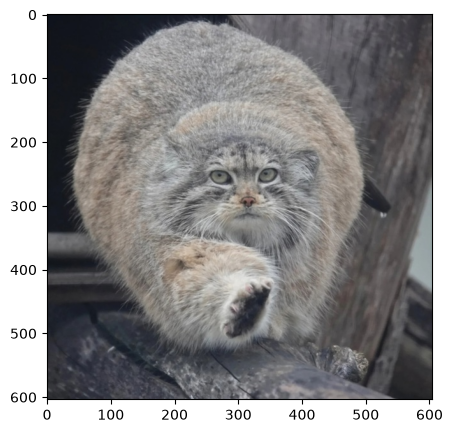

In [12]:
img = cv2.imread('../data/manul.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)

### White patch
In white patch algorithm we choose a group of pixels we know they should be white. We then scale the resulting image colour channels by this white patch.

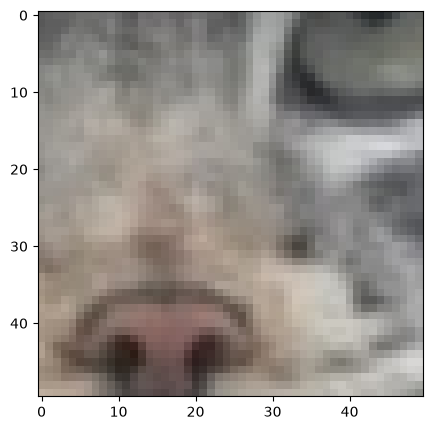

In [28]:
plt.imshow(img[250:300, 300:350])

(<Axes: >, <matplotlib.image.AxesImage at 0x173dd8450>)

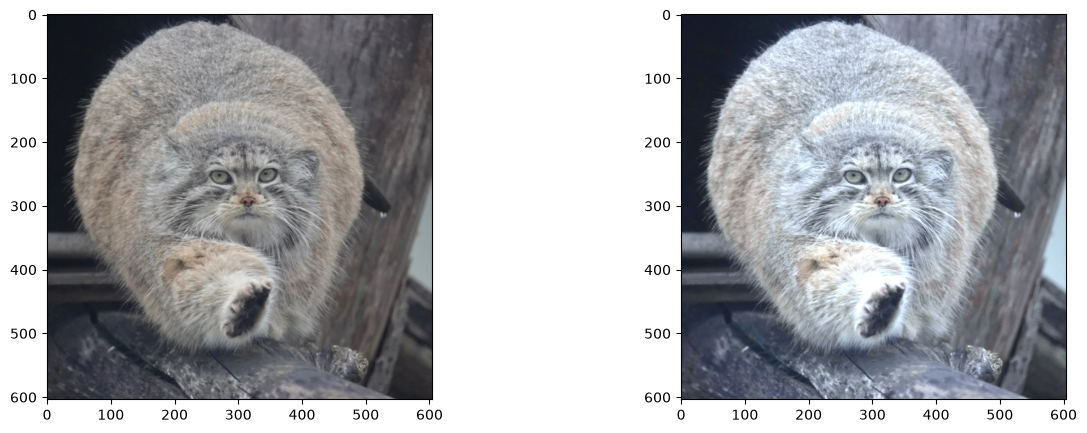

In [29]:
# Define white patch and the coefficients
row, col = 393, 265
white = img[row, col, :]
coeffs = 255.0/white

# Apply white balancing and generate balanced image
balanced = np.zeros_like(img, dtype=np.float32)
for channel in range(3):
    balanced[..., channel] = img[..., channel] * coeffs[channel]

# White patching does not guarantee that the dynamic range is preserved, images must be clipped.
balanced = balanced/255
balanced[balanced > 1] = 1

plt.subplot(121), plt.imshow(img)
plt.subplot(122), plt.imshow(balanced)

### Gray world
This algorithm assumes that a scene, on average, is gray.

(<Axes: >, <matplotlib.image.AxesImage at 0x157d94790>)

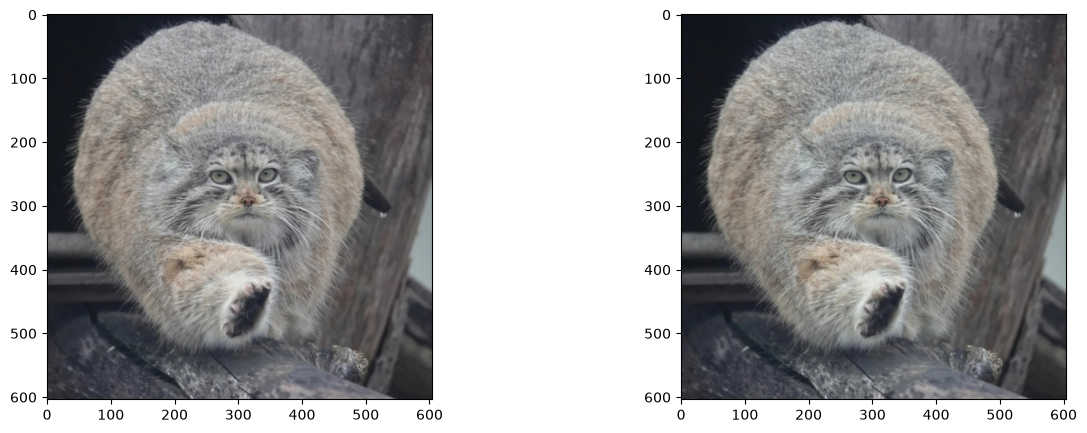

In [14]:
# Load your image
img = cv2.imread('../data/manul.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Compute the mean values for all three colour channels (red, green, blue)
mean_r = np.mean(img[:,:,0])
mean_g = np.mean(img[:,:,1])
mean_b = np.mean(img[:,:,2])

# Compute the coefficients kr, kg, kb
# Note: there are 3 coefficients to compute but we only have 2 equations.
# Therefore, you have to make an assumption, fix the value of one of the
# coefficients and compute the remining two
# Hint: You can fix the coefficient of the brightest colour channel to 1.
kr = max(mean_r, mean_g, mean_b) / mean_r
kg = max(mean_r, mean_g, mean_b) / mean_g
kb = max(mean_r, mean_g, mean_b) / mean_b

# Apply color balancing and generate the balanced image
balanced = np.clip((img * [kr, kg, kb]) / 255.0, 0, 1)

# Show the original and the balanced image side by side
plt.subplot(121), plt.imshow(img)
plt.subplot(122), plt.imshow(balanced)

### Scale-by-min-max
This is a straightforward algorithm that scales each colour channel by its maximum value. Note that it is sensitive to noise and saturations.

(<Axes: >, <matplotlib.image.AxesImage at 0x157d11010>)

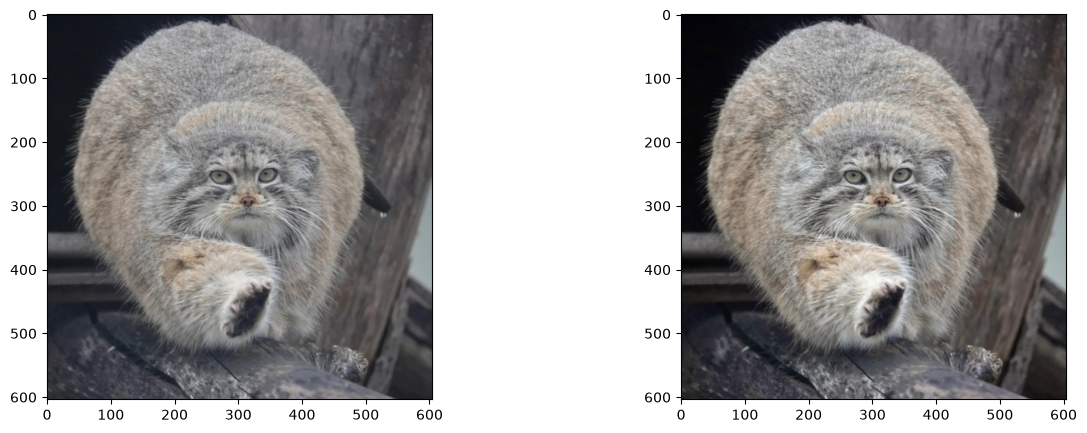

In [15]:
# Load your image
img = cv2.imread('../data/manul.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Compute the minimum values for all three colour channels (red, green, blue)
min_r = np.min(img[:,:,0])
min_g = np.min(img[:,:,1])
min_b = np.min(img[:,:,2])


# Compute the maximum values for all three colour channels (red, green, blue)
max_r = np.max(img[:,:,0])
max_g = np.max(img[:,:,1])
max_b = np.max(img[:,:,2])


# Apply scale-by-max balancing and generate the balanced image
balanced = np.clip((img - [min_r, min_g, min_b]) / np.array([max_r - min_r, max_g - min_g, max_b - min_b], dtype=float), 0, 1)

plt.subplot(121), plt.imshow(img)
plt.subplot(122), plt.imshow(balanced)